# M8a · DFD preprocessing for cross-dataset testing (face crops)

**Goal.** Turn the Google DeepFakeDetection (DFD) videos into face crops made exactly like our FF++ training crops (M0), so M8b can score the existing FF++-trained checkpoints on DFD. No training here.

**Why DFD.** LNCLIP-DF / GenD (Yermakov et al., WACV 2026) tests FF++-trained models on DFD with 363 real + 3068 fake videos (Table 1) and reports video AUC 96.4 for GenD-CLIP (Table 4).

**Pipeline (same as M0 unless stated):**

| step | M0 (FF++) | M8a (DFD) |
|---|---|---|
| frames | 32 per video, pre-extracted JPEGs in `frames_all` | 32 evenly spaced frames decoded from the video, then a JPEG round trip at the quality measured on `frames_all` (section 3) |
| face detector | MTCNN, largest face with prob ≥ 0.9, missing frames take the nearest detected box | same |
| crop | 1.3× square box, 224×224, PNG | same |
| fakes | cropped with their real video's boxes (FF++ fakes are frame-aligned with their source) | **detected independently** per video (DFD fakes are not guaranteed frame-aligned with the actor clips; standard cross-dataset practice) |

**Known DFD issue.** Some scenes have two people (hugging, meeting, conversation). Only one face is swapped in a fake; the largest face may be the untouched person. This affects every model equally. M8a records how many confident faces each frame has, so M8b can report per-scene AUC.

**Inputs (read only):** `dfd_c23/` (videos), `ffc23dataset/frames_all/` (only to measure JPEG quality and check sampling).
**Outputs:** `DATA_ROOT/faces_dfd/`, `DATA_ROOT/index/dfd_c23.csv`, `DATA_ROOT/runs/m8a/`.

| Section | What it does | Run time |
|---|---|---|
| 1 | settings, imports, environment | seconds |
| 2 | inventory: find and label the videos, read video metadata | ~2–5 min |
| 3 | match the FF++ frame pipeline: JPEG quality, frame sampling | ~2 min |
| 4 | face extraction: helpers, smoke test, full run (resumable) | ~30–60 min |
| 5 | extraction status, failures, faces per frame | seconds |
| 6 | build the index CSV, summary, example crops | ~1 min |

## 1. Setup

### 1.1 Paths and settings

Crop settings are copied from M0 and must not be changed, otherwise DFD crops would differ from the training crops.

In [1]:
# 1.1 Paths and settings
from pathlib import Path

# inputs (read only)
DFD_ROOT = Path("/nlsasfs/home/isea/isea64/dfd_c23")
FRAMES_ALL = Path("/nlsasfs/home/isea/isea64/ffc23dataset/frames_all")
FRAMES_ALL_DFD = FRAMES_ALL / "DeepFakeDetection"   # 1000 DFD fakes, same extraction tool as our FF++ frames

# outputs (ours)
DATA_ROOT = Path("/nlsasfs/home/isea/isea64/GBLA-Deepfake Detection")
FACES_ROOT = DATA_ROOT / "faces_dfd"
INDEX_CSV = DATA_ROOT / "index" / "dfd_c23.csv"
RUN_DIR = DATA_ROOT / "runs" / "m8a"

EXPECTED_REAL, EXPECTED_FAKE = 363, 3068

# same as M0
FRAMES_PER_VIDEO = 32
CROP_SCALE = 1.3
IMAGE_SIZE = 224
IMAGE_FORMAT = "png"
MIN_FACE_PROB = 0.9
DETECTOR_BATCH = 16

LOAD_WORKERS = 8         # threads decoding videos while the GPU detects faces
META_WORKERS = 16        # threads reading video metadata in section 2
RETRY_FAILED = False     # True = retry videos marked as failed (no face / unreadable) in an earlier run
SEED = 0

for d in (FACES_ROOT, INDEX_CSV.parent, RUN_DIR):
    d.mkdir(parents=True, exist_ok=True)
print("outputs go to:", FACES_ROOT, "|", INDEX_CSV, "|", RUN_DIR)

outputs go to: /nlsasfs/home/isea/isea64/GBLA-Deepfake Detection/faces_dfd | /nlsasfs/home/isea/isea64/GBLA-Deepfake Detection/index/dfd_c23.csv | /nlsasfs/home/isea/isea64/GBLA-Deepfake Detection/runs/m8a


### 1.2 Imports and environment

`facenet-pytorch` was installed in M0 (`--no-deps`). If the import fails, run `%pip install -q --no-deps facenet-pytorch` once and restart the kernel.

In [2]:
# 1.2 Imports and environment
import json, os, platform, random, re, sys, time
from collections import Counter, deque
from concurrent.futures import ThreadPoolExecutor
from importlib.metadata import version
from itertools import islice

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from PIL import Image
from tqdm.auto import tqdm
from facenet_pytorch import MTCNN

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

env = {
    "python": platform.python_version(),
    "torch": torch.__version__,
    "opencv": cv2.__version__,
    "facenet-pytorch": version("facenet-pytorch"),
    "pillow": Image.__version__,
    "GPU": torch.cuda.get_device_name(0) if DEVICE == "cuda" else None,
}
display(pd.Series(env, name="value").to_frame())
(RUN_DIR / "environment.json").write_text(json.dumps(env, indent=2))

/nlsasfs/home/isea/isea64/venv_jupyter/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,value
python,3.10.12
torch,2.6.0+cu124
opencv,5.0.0
facenet-pytorch,2.6.0
pillow,12.3.0
GPU,NVIDIA A100-SXM4-40GB


158

## 2. Inventory

Videos are labelled from the official DFD file names, so the folder layout does not matter:

- real: `<actor>__<scene>.mp4`, e.g. `01__meeting_serious.mp4`
- fake: `<target>_<source>__<scene>__<experiment id>.mp4`, e.g. `01_02__meeting_serious__YVGY8LOK.mp4` (the face of actor `<target>` is replaced by `<source>`)

Expected: 363 real, 3068 fake, 0 unrecognised names, 0 duplicates. The originals folder listed 364 entries; the non-video entry is printed here.

In [3]:
# 2.1 Find and label the videos
REAL_RE = re.compile(r"^\d{2}__[^_].*$")
FAKE_RE = re.compile(r"^\d{2}_\d{2}__.+__[A-Z0-9]{8}$")

rows, unrecognised = [], []
for p in sorted(DFD_ROOT.rglob("*.mp4")):
    stem = p.stem
    if REAL_RE.match(stem):
        label = 0
    elif FAKE_RE.match(stem):
        label = 1
    else:
        unrecognised.append(str(p.relative_to(DFD_ROOT)))
        continue
    head, scene = stem.split("__")[:2]
    ids = head.split("_")
    rows.append({"video_id": stem, "label": label, "target_id": ids[0],
                 "source_id": ids[1] if label else "", "scene": scene,
                 "pair_video": f"{ids[0]}__{scene}" if label else "",
                 "path": str(p), "size_mb": p.stat().st_size / 1e6})
videos = pd.DataFrame(rows)

for folder in sorted({p.parent for p in DFD_ROOT.rglob("*.mp4")}):
    extra = [q.name for q in folder.iterdir() if q.suffix.lower() != ".mp4"]
    print(f"{folder.relative_to(DFD_ROOT)}: {sum(1 for _ in folder.glob('*.mp4'))} mp4",
          f"| other entries: {extra}" if extra else "")

n_real, n_fake = (videos.label == 0).sum(), (videos.label == 1).sum()
dups = int(videos.video_id.duplicated().sum())
real_ids = set(videos.loc[videos.label == 0, "video_id"])
unpaired = int((~videos.loc[videos.label == 1, "pair_video"].isin(real_ids)).sum())

print(f"\nreal: {n_real} (expected {EXPECTED_REAL})   fake: {n_fake} (expected {EXPECTED_FAKE})")
print(f"unrecognised names: {len(unrecognised)} {unrecognised[:5]}   duplicate ids: {dups}")
print(f"actors: {videos.target_id.nunique()}   scenes: {videos.scene.nunique()}")
print(f"fakes whose actor + scene has no real clip: {unpaired}")
print("\nsize (MB) per class:")
display(videos.groupby("label").size_mb.describe().round(2))
print(f"total: real {videos[videos.label == 0].size_mb.sum() / 1e3:.2f} GB, fake {videos[videos.label == 1].size_mb.sum() / 1e3:.2f} GB "
      "(official c23: ~3 GB real, ~22 GB fake; c40 would be ~0.4 / ~3 GB; raw ~200 GB / ~1.6 TB)")

assert dups == 0, "duplicate video ids"
assert (n_real, n_fake) == (EXPECTED_REAL, EXPECTED_FAKE), "counts differ from official DFD; stop and report"

DFD_manipulated_sequences/DFD_manipulated_sequences: 3068 mp4 
DFD_original_sequences: 363 mp4 | other entries: ['tmp51ews_lu']

real: 363 (expected 363)   fake: 3068 (expected 3068)
unrecognised names: 0 []   duplicate ids: 0
actors: 28   scenes: 16
fakes whose actor + scene has no real clip: 0

size (MB) per class:


,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
0,363.0,7.99,5.39,1.47,4.42,6.47,8.93,28.93
1,3068.0,6.93,5.02,0.16,3.33,5.75,8.24,27.02


total: real 2.90 GB, fake 21.27 GB (official c23: ~3 GB real, ~22 GB fake; c40 would be ~0.4 / ~3 GB; raw ~200 GB / ~1.6 TB)


In [4]:
# 2.2 Video metadata (frame count, fps, resolution)
def video_meta(path):
    cap = cv2.VideoCapture(path)
    meta = {"opened": cap.isOpened(),
            "n_frames": int(cap.get(cv2.CAP_PROP_FRAME_COUNT)),
            "fps": cap.get(cv2.CAP_PROP_FPS),
            "width": int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)),
            "height": int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))}
    cap.release()
    return meta

with ThreadPoolExecutor(META_WORKERS) as pool:
    metas = list(tqdm(pool.map(video_meta, videos.path), total=len(videos), desc="metadata"))
videos = pd.concat([videos.drop(columns=[c for c in ("opened", "n_frames", "fps", "width", "height") if c in videos]),
                    pd.DataFrame(metas)], axis=1)
videos["duration_s"] = videos.n_frames / videos.fps.replace(0, np.nan)
videos.to_csv(RUN_DIR / "videos.csv", index=False)

print("unreadable videos:", int((~videos.opened).sum()), "| fewer frames than 32:", int((videos.n_frames < FRAMES_PER_VIDEO).sum()))
print("\nresolution per class:")
display(videos.assign(res=videos.width.astype(str) + "x" + videos.height.astype(str))
        .groupby(["label", "res"]).size().unstack(0).fillna(0).astype(int))
print("frames / duration per class:")
display(videos.groupby("label")[["n_frames", "fps", "duration_s"]].describe().T.round(1))

metadata: 100%|██████████| 3431/3431 [01:43<00:00, 33.13it/s]


unreadable videos: 0 | fewer frames than 32: 19

resolution per class:


label,0,1
res,,
1920x1080,363,3068


frames / duration per class:


label                  0       1
n_frames   count   363.0  3068.0
           mean    868.8   731.0
           std     284.3   322.5
           min     159.0     5.0
           25%     694.5   481.8
           50%     850.0   724.5
           75%    1034.5   911.2
           max    1620.0  1620.0
fps        count   363.0  3068.0
           mean     24.0    24.0
           std       0.0     0.0
           min      24.0    24.0
           25%      24.0    24.0
           50%      24.0    24.0
           75%      24.0    24.0
           max      24.0    24.0
duration_s count   363.0  3068.0
           mean     36.2    30.5
           std      11.8    13.4
           min       6.6     0.2
           25%      28.9    20.1
           50%      35.4    30.2
           75%      43.1    38.0
           max      67.5    67.5

## 3. Match the FF++ frame pipeline

Our FF++ training crops were cut from JPEG frames in `frames_all`, not from decoded video. JPEG adds its own compression artifacts, and a detector trained on them could react to their absence. So we:

1. **Measure the JPEG quality** of `frames_all` images from the quantization tables (IJG scale; order-independent estimate).
2. **Check frame sampling and the JPEG round trip** on DFD fakes that exist both as video (ours) and as `frames_all` images. For each `frames_all` image we find the best-matching decoded frame, compare it with our sampling rule (32 evenly spaced indices, as in M0), and compare pixel error with and without our JPEG round trip.

Expected: sampling rule matches (or is off by ≤ 1 frame), image size equals video size, and the JPEG round trip lowers the pixel error.

In [5]:
# 3.1 JPEG quality of frames_all
STD_LUMA = [16, 11, 10, 16, 24, 40, 51, 61, 12, 12, 14, 19, 26, 58, 60, 55,
            14, 13, 16, 24, 40, 57, 69, 56, 14, 17, 22, 29, 51, 87, 80, 62,
            18, 22, 37, 56, 68, 109, 103, 77, 24, 35, 55, 64, 81, 104, 113, 92,
            49, 64, 78, 87, 103, 121, 120, 101, 72, 92, 95, 98, 112, 100, 103, 99]


def jpeg_quality(path):
    """IJG quality estimated from the luminance quantization table (None if not a JPEG)."""
    with Image.open(path) as im:
        tables = getattr(im, "quantization", None)
        subsampling = None
        try:
            from PIL import JpegImagePlugin
            subsampling = JpegImagePlugin.get_sampling(im)
        except Exception:
            pass
    if not tables:
        return None, subsampling
    scale = 100 * sum(tables[0]) / sum(STD_LUMA)
    q = (200 - scale) / 2 if scale <= 100 else 5000 / scale
    return int(round(min(max(q, 1), 100))), subsampling


rng = random.Random(SEED)
q_rows = []
for folder in sorted(p for p in FRAMES_ALL.iterdir() if p.is_dir()):
    files = [f for f in islice(folder.iterdir(), 5000) if f.suffix.lower() in (".jpg", ".jpeg")]
    for f in rng.sample(files, min(20, len(files))):
        q, ss = jpeg_quality(f)
        q_rows.append({"folder": folder.name, "quality": q, "subsampling": ss})
q_df = pd.DataFrame(q_rows)
display(q_df.groupby(["folder", "quality", "subsampling"]).size().rename("images").to_frame())

JPEG_QUALITY = int(q_df.quality.mode()[0])
SUBSAMPLING = int(q_df.subsampling.mode()[0]) if q_df.subsampling.notna().any() else None
print(f"JPEG_QUALITY = {JPEG_QUALITY}   chroma subsampling code = {SUBSAMPLING} (0 = 4:4:4, 1 = 4:2:2, 2 = 4:2:0)")

,,,images
folder,quality,subsampling,
DeepFakeDetection,95,2,20
Deepfakes,95,2,20
Face2Face,95,2,20
FaceShifter,95,2,20
FaceSwap,95,2,20
NeuralTextures,95,2,20
original,95,2,20


JPEG_QUALITY = 95   chroma subsampling code = 2 (0 = 4:4:4, 1 = 4:2:2, 2 = 4:2:0)


In [6]:
# 3.2 Sampling and JPEG round-trip check on DFD fakes present in both places
N_CHECK = 3


def sample_indices(n_frames, k=FRAMES_PER_VIDEO):
    """Same rule as M0."""
    if n_frames <= 0:
        return []
    return sorted(set(np.linspace(0, n_frames - 1, min(k, n_frames)).round().astype(int).tolist()))


def jpeg_roundtrip(rgb, quality=None):
    """Encode/decode with Pillow at the frames_all quality (identity if quality is None)."""
    if quality is None:
        return rgb
    import io
    buf = io.BytesIO()
    kw = {"quality": quality}
    if SUBSAMPLING is not None:
        kw["subsampling"] = SUBSAMPLING
    Image.fromarray(rgb).save(buf, format="JPEG", **kw)
    return np.array(Image.open(io.BytesIO(buf.getvalue())).convert("RGB"))


def small_gray(rgb):
    return cv2.resize(cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY), (96, 54), interpolation=cv2.INTER_AREA).astype(np.float32)


def frames_all_files(vid):
    out = {}
    for f in FRAMES_ALL_DFD.glob(f"{vid}_frame_*"):
        m = re.match(rf"^{re.escape(vid)}_frame_(\d+)$", f.stem)
        if m:
            out[int(m.group(1))] = f
    return dict(sorted(out.items()))


fakes = videos[videos.label == 1]
overlap = [r for r in fakes.itertuples() if (FRAMES_ALL_DFD / f"{r.video_id}_frame_00.jpg").exists()]
print(f"DFD fakes present in frames_all: {len(overlap)} of {len(fakes)}")

check_rows = []
for r in random.Random(SEED).sample(overlap, min(N_CHECK, len(overlap))):
    ref = frames_all_files(r.video_id)
    ref_rgb = {k: cv2.cvtColor(cv2.imread(str(f)), cv2.COLOR_BGR2RGB) for k, f in ref.items()}
    ref_small = {k: small_gray(v) for k, v in ref_rgb.items()}

    cap = cv2.VideoCapture(r.path)
    smalls = []
    while True:
        ok, frame = cap.read()
        if not ok:
            break
        smalls.append(small_gray(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)))
    cap.release()
    smalls = np.stack(smalls)
    rule = sample_indices(r.n_frames)
    best = {k: int(np.abs(smalls - s).mean(axis=(1, 2)).argmin()) for k, s in ref_small.items()}

    wanted = {rule[k] for k in ref if k < len(rule)}
    decoded, cap, i = {}, cv2.VideoCapture(r.path), 0
    while i <= max(wanted) and cap.grab():
        if i in wanted:
            decoded[i] = cv2.cvtColor(cap.retrieve()[1], cv2.COLOR_BGR2RGB)
        i += 1
    cap.release()
    mae_raw, mae_jpeg = [], []
    for k, img in ref_rgb.items():
        if k < len(rule) and rule[k] in decoded and decoded[rule[k]].shape == img.shape:
            d = decoded[rule[k]]
            mae_raw.append(np.abs(d.astype(np.int16) - img).mean())
            mae_jpeg.append(np.abs(jpeg_roundtrip(d, JPEG_QUALITY).astype(np.int16) - img).mean())

    diffs = [best[k] - rule[k] for k in ref if k < len(rule)]
    check_rows.append({
        "video": r.video_id,
        "video size": (r.width, r.height),
        "frames_all size": next(iter(ref_rgb.values())).shape[1::-1],
        "frames (header / decoded)": f"{r.n_frames} / {len(smalls)}",
        "frames_all images": len(ref),
        "rule == best match": f"{sum(d == 0 for d in diffs)}/{len(diffs)}",
        "max |best - rule|": max(map(abs, diffs)) if diffs else None,
        "MAE raw decode": round(float(np.mean(mae_raw)), 3) if mae_raw else None,
        f"MAE after JPEG q{JPEG_QUALITY}": round(float(np.mean(mae_jpeg)), 3) if mae_jpeg else None,
    })

pipeline_check = pd.DataFrame(check_rows)
display(pipeline_check)
pipeline_check.to_csv(RUN_DIR / "pipeline_check.csv", index=False)

USE_JPEG = bool(len(pipeline_check)) and (pipeline_check.iloc[:, -1] <= pipeline_check.iloc[:, -2]).all()
print("JPEG round trip:", f"ON (q={JPEG_QUALITY})" if USE_JPEG else "OFF (did not reduce the error; report this)")

DFD fakes present in frames_all: 1000 of 3068


,video,video size,frames_all size,frames (header / decoded),frames_all images,rule == best match,max |best - rule|,MAE raw decode,MAE after JPEG q95
0,24_19__secret_conversation__NPZW2Z9L,"(1920, 1080)","(1920, 1080)",11 / 11,32,1/11,7,4.955,4.614
1,11_01__talking_against_wall__4OJNJLOO,"(1920, 1080)","(1920, 1080)",880 / 880,32,17/32,1,0.850,0.188
2,20_26__talking_angry_couch__34DJQS3E,"(1920, 1080)","(1920, 1080)",1618 / 1618,32,17/32,1,1.460,0.870


JPEG round trip: ON (q=95)


## 4. Face extraction

Per video: decode the 32 sampled frames → JPEG round trip (if ON) → MTCNN on every frame → largest confident face, missing frames take the nearest detected box → 1.3× square → 224×224 PNG at `faces_dfd/<real|fake>/<video id>/<key>.png`. The key is the frame's position 0–31 (as in M0); the decoded frame index is stored in the box file.

**Resume safety (as M0).** `_done` / `_failed` markers per video, boxes saved before crops, temp-file-then-rename writes, errors logged to `faces_dfd/extraction_log.tsv` and retried on the next run.

### 4.1 Helpers

In [7]:
# 4.1 Helpers (frame reading, boxes and resume logic follow M0)
PIPELINE = {"frames_per_video": FRAMES_PER_VIDEO, "crop_scale": CROP_SCALE, "image_size": IMAGE_SIZE,
            "min_face_prob": MIN_FACE_PROB, "jpeg_quality": JPEG_QUALITY if USE_JPEG else None,
            "subsampling": SUBSAMPLING if USE_JPEG else None, "fake_boxes": "independent"}
PIPELINE_FILE = FACES_ROOT / "pipeline.json"
if PIPELINE_FILE.exists():
    saved = json.loads(PIPELINE_FILE.read_text())
    assert saved == PIPELINE, f"faces_dfd was made with different settings:\n{saved}\nvs now:\n{PIPELINE}"
else:
    PIPELINE_FILE.write_text(json.dumps(PIPELINE, indent=2))
print("pipeline:", PIPELINE)

BOX_DIR = FACES_ROOT / "_boxes"
BOX_DIR.mkdir(parents=True, exist_ok=True)
SAVE_FORMAT = Image.registered_extensions()["." + IMAGE_FORMAT]
VIDEO = videos.set_index("video_id")


def out_dir_of(vid):
    return FACES_ROOT / ("fake" if VIDEO.at[vid, "label"] else "real") / vid


def read_frames(path, indices):
    """Decode sequentially (seeking is unreliable for some codecs) and keep the wanted frames."""
    wanted, last, frames = set(indices), max(indices, default=-1), {}
    cap = cv2.VideoCapture(str(path))
    i = 0
    while i <= last and cap.grab():
        if i in wanted:
            ok, frame = cap.retrieve()
            if ok:
                frames[i] = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        i += 1
    cap.release()
    return frames


def load_keyed_frames(vid, key_to_index):
    """{key: RGB frame after the JPEG round trip} for the requested keys."""
    raw = read_frames(VIDEO.at[vid, "path"], sorted(set(key_to_index.values())))
    q = PIPELINE["jpeg_quality"]
    return {k: jpeg_roundtrip(raw[i], q) for k, i in key_to_index.items() if i in raw}


def pick_face(boxes, probs):
    """(largest confident face or None, number of confident faces)."""
    if boxes is None:
        return None, 0
    confident = [b for b, p in zip(boxes, probs) if p is not None and p >= MIN_FACE_PROB]
    if not confident:
        return None, 0
    best = max(confident, key=lambda b: (b[2] - b[0]) * (b[3] - b[1]))
    return [float(v) for v in best], len(confident)


def fill_missing(raw):
    """Frames without a detection take the box of the nearest frame that has one."""
    found = [i for i, b in raw.items() if b is not None]
    if not found:
        return None
    return {i: b if b is not None else raw[min(found, key=lambda j: abs(j - i))]
            for i, b in raw.items()}


def square_box(box, width, height):
    x0, y0, x1, y1 = box
    cx, cy = (x0 + x1) / 2, (y0 + y1) / 2
    side = min(max(x1 - x0, y1 - y0) * CROP_SCALE, width, height)
    left = int(round(min(max(cx - side / 2, 0), width - side)))
    top = int(round(min(max(cy - side / 2, 0), height - side)))
    s = int(round(side))
    return [left, top, left + s, top + s]


def crop_path(out_dir, key):
    return out_dir / f"{key:04d}.{IMAGE_FORMAT}"


def save_crop(frame, box, out_path):
    x0, y0, x1, y1 = box
    tmp = out_path.with_name(out_path.name + ".tmp")
    Image.fromarray(frame[y0:y1, x0:x1]).resize((IMAGE_SIZE, IMAGE_SIZE), Image.BICUBIC).save(tmp, format=SAVE_FORMAT)
    os.replace(tmp, out_path)


def write_json(path, obj):
    tmp = path.with_name(path.name + ".tmp")
    tmp.write_text(json.dumps(obj))
    os.replace(tmp, path)


def load_boxes(vid):
    path = BOX_DIR / f"{vid}.json"
    return json.loads(path.read_text()) if path.exists() else None


def missing_crops(out_dir, keys):
    return [k for k in sorted(keys) if not crop_path(out_dir, k).exists()]


def video_state(out_dir):
    if (out_dir / "_done").exists():
        return "done"
    if (out_dir / "_failed").exists() and not RETRY_FAILED:
        return "failed"
    return "todo"


def mark_done(out_dir, n_missing=0):
    (out_dir / "_failed").unlink(missing_ok=True)
    (out_dir / "_done").write_text(str(n_missing))


def mark_failed(out_dir, reason):
    out_dir.mkdir(parents=True, exist_ok=True)
    (out_dir / "_failed").write_text(reason)


def log_event(video_id, message):
    with open(FACES_ROOT / "extraction_log.tsv", "a") as f:
        f.write(f"{time.strftime('%Y-%m-%d %H:%M:%S')}\t{video_id}\t{message}\n")


def bounded_map(fn, items, workers):
    """Threaded map that holds at most 2 x workers results in memory (frames are large)."""
    items = iter(items)
    with ThreadPoolExecutor(workers) as pool:
        pending = deque(pool.submit(fn, x) for x in islice(items, 2 * workers))
        while pending:
            result = pending.popleft().result()
            for x in islice(items, 1):
                pending.append(pool.submit(fn, x))
            yield result

pipeline: {'frames_per_video': 32, 'crop_scale': 1.3, 'image_size': 224, 'min_face_prob': 0.9, 'jpeg_quality': 95, 'subsampling': 2, 'fake_boxes': 'independent'}


In [8]:
# 4.2 Detection and the extraction loop
mtcnn = MTCNN(keep_all=True, device=DEVICE, post_process=False)


def load_video(vid):
    """Background thread: decode only the frames this video still needs.
    Returns (vid, status, payload, boxes); payload = {key: frame} or the error text."""
    out_dir = out_dir_of(vid)
    state = video_state(out_dir)
    if state != "todo":
        return vid, state, None, None
    try:
        boxes = load_boxes(vid)
        if boxes is not None:
            todo = missing_crops(out_dir, [int(k) for k in boxes["boxes"]])
            return vid, "resume", load_keyed_frames(vid, {k: boxes["frame_index"][str(k)] for k in todo}), boxes
        idx = sample_indices(int(VIDEO.at[vid, "n_frames"]))
        return vid, "new", load_keyed_frames(vid, dict(enumerate(idx))), {"frame_index": {str(k): i for k, i in enumerate(idx)}}
    except Exception as e:
        return vid, "error", repr(e), None


def detect_boxes(frames):
    """({key: square box}, (width, height), {key: confident faces}) or None if no face in any frame."""
    keys = sorted(frames)
    raw, n_faces = {}, {}
    for start in range(0, len(keys), DETECTOR_BATCH):
        chunk = keys[start:start + DETECTOR_BATCH]
        boxes, probs = mtcnn.detect([Image.fromarray(frames[k]) for k in chunk])
        for k, b, p in zip(chunk, boxes, probs):
            raw[k], n_faces[k] = pick_face(b, p)
    filled = fill_missing(raw)
    if filled is None:
        return None
    h, w = frames[keys[0]].shape[:2]
    return {k: square_box(filled[k], w, h) for k in keys}, (w, h), n_faces


def run_videos(vids):
    stats = Counter()
    for vid, status, payload, meta in tqdm(bounded_map(load_video, vids, LOAD_WORKERS), total=len(vids), desc="videos"):
        out_dir = out_dir_of(vid)
        if status in ("done", "failed"):
            stats[f"skipped ({status} earlier)"] += 1
            continue
        if status == "error":
            stats["error (retried next run)"] += 1
            log_event(vid, f"error: {payload}")
            continue
        try:
            frames = payload
            if status == "new":
                if not frames:
                    mark_failed(out_dir, "unreadable"); log_event(vid, "failed: unreadable")
                    stats["failed: unreadable"] += 1
                    continue
                detected = detect_boxes(frames)
                if detected is None:
                    mark_failed(out_dir, "no_face"); log_event(vid, "failed: no_face")
                    stats["failed: no_face"] += 1
                    continue
                crops, (w, h), n_faces = detected
                meta = {"size": [w, h],
                        "boxes": {str(k): b for k, b in crops.items()},
                        "frame_index": {str(k): meta["frame_index"][str(k)] for k in crops},
                        "n_faces": {str(k): n for k, n in n_faces.items()}}
                write_json(BOX_DIR / f"{vid}.json", meta)

            out_dir.mkdir(parents=True, exist_ok=True)
            for k, frame in frames.items():
                save_crop(frame, meta["boxes"][str(k)], crop_path(out_dir, k))
            keys = [int(k) for k in meta["boxes"]]
            left = missing_crops(out_dir, keys)
            if len(left) == len(keys):
                mark_failed(out_dir, "unreadable"); log_event(vid, "failed: unreadable")
                stats["failed: unreadable"] += 1
                continue
            mark_done(out_dir, len(left))
            stats["extracted" if status == "new" else "resumed (only missing crops)"] += 1
        except Exception as e:
            stats["error (retried next run)"] += 1
            log_event(vid, f"error: {e!r}")
    print(dict(stats))
    return stats

### 4.3 Smoke test: 2 real + 2 fake (one two-person scene each)

Look at the crops: one face per crop, centred, similar framing to the FF++ crops. Uses the same output folders, so the full run skips these videos.

videos: 100%|██████████| 4/4 [00:39<00:00,  9.87s/it]


{'extracted': 4}
9.9 s per video -> full run ~565 min (an upper bound: the full run overlaps decoding in 8 threads)


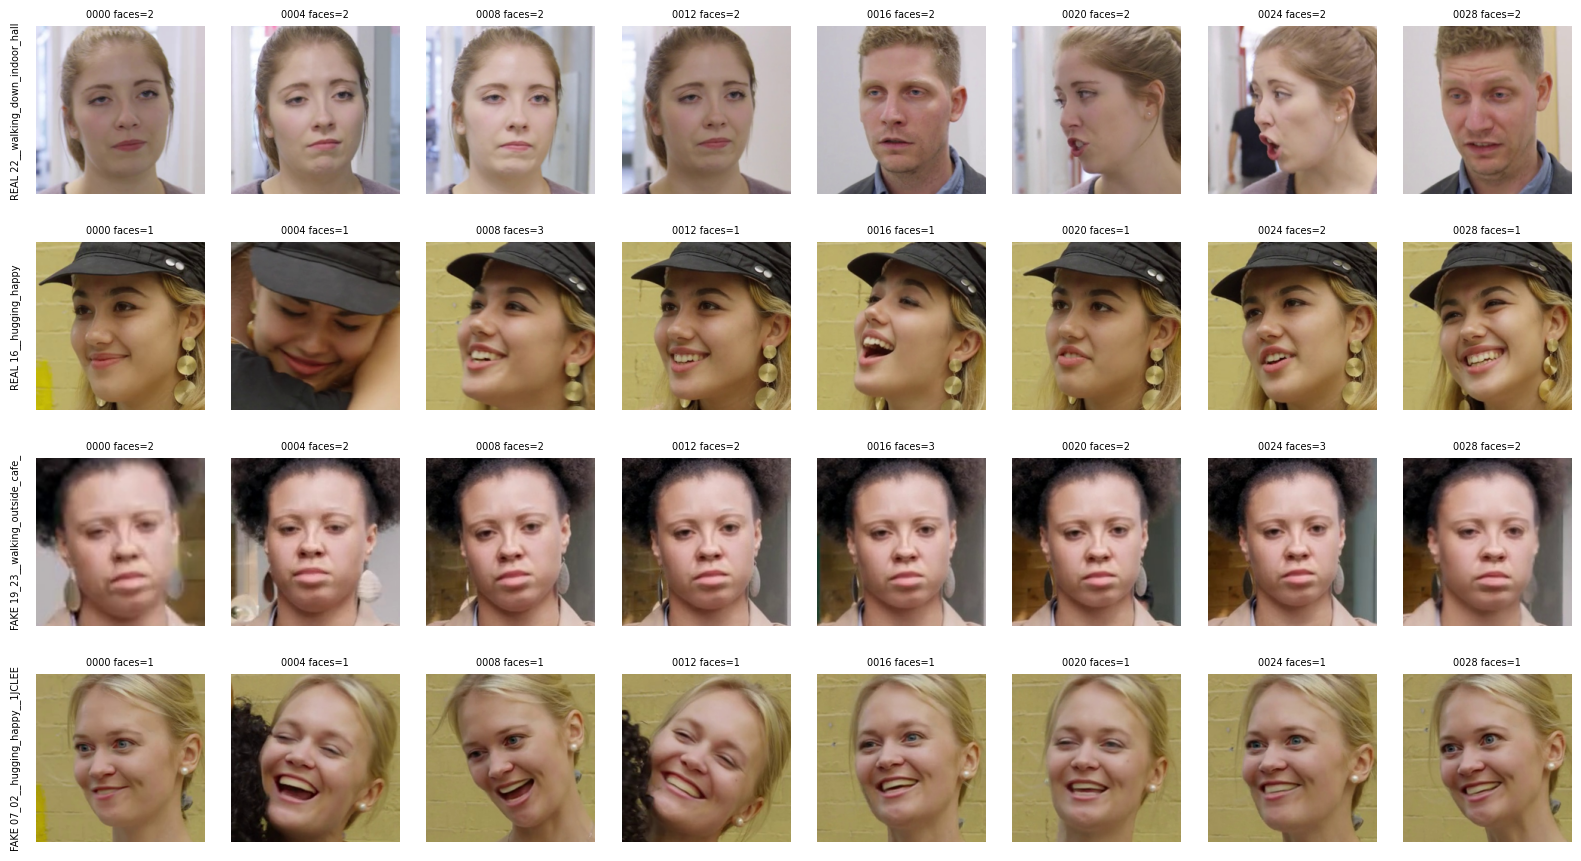

In [9]:
# 4.3 Smoke test
TWO_PERSON = ("hugging", "meeting", "secret_conversation")
pick = []
for label in (0, 1):
    part = videos[videos.label == label]
    two = part[part.scene.str.contains("|".join(TWO_PERSON))]
    one = part[~part.scene.str.contains("|".join(TWO_PERSON))]
    pick += [one.sample(1, random_state=SEED).video_id.item(), two.sample(1, random_state=SEED).video_id.item()]

t0 = time.time()
run_videos(pick)
print(f"{(time.time() - t0) / len(pick):.1f} s per video -> full run ~{(time.time() - t0) / len(pick) * len(videos) / 60:.0f} min "
      f"(an upper bound: the full run overlaps decoding in {LOAD_WORKERS} threads)")

fig, axes = plt.subplots(len(pick), 8, figsize=(16, 2.2 * len(pick)))
for row, vid in zip(axes, pick):
    crops = sorted(out_dir_of(vid).glob(f"*.{IMAGE_FORMAT}"))
    meta = load_boxes(vid) or {"n_faces": {}}
    for ax, c in zip(row, crops[::4]):
        ax.imshow(Image.open(c)); ax.axis("off")
        ax.set_title(f"{c.stem} faces={meta['n_faces'].get(str(int(c.stem)), '?')}", fontsize=7)
    row[0].text(-20, IMAGE_SIZE / 2, ("FAKE " if VIDEO.at[vid, "label"] else "REAL ") + vid[:28],
                rotation=90, va="center", ha="right", fontsize=7)
plt.tight_layout(); plt.show()

### 4.4 Full run

Resumable: if the session ends, rerun sections 1, 2, 3.1–3.2 (fast), 4.1, 4.2 and this cell. Finished videos are skipped. Real videos run first.

In [10]:
# 4.4 Full run
t0 = time.time()
order = videos.sort_values(["label", "video_id"]).video_id.tolist()
run_stats = run_videos(order)
print(f"took {(time.time() - t0) / 60:.1f} min")

videos: 100%|██████████| 3431/3431 [2:06:58<00:00,  2.22s/it]  

{'extracted': 3427, 'skipped (done earlier)': 4}
took 127.0 min


## 5. Extraction status

Expected: all 3431 videos `done`, few or no failures (the paper lost 2 fakes to face-detector failures). `frames with ≥2 faces` shows how common two-person frames are per scene.

In [11]:
# 5. Status
status_rows = []
for r in videos.itertuples():
    d = out_dir_of(r.video_id)
    state = "done" if (d / "_done").exists() else "failed" if (d / "_failed").exists() else "todo"
    meta = load_boxes(r.video_id) or {}
    nf = list(meta.get("n_faces", {}).values())
    status_rows.append({"video_id": r.video_id, "label": r.label, "scene": r.scene, "state": state,
                        "reason": (d / "_failed").read_text() if state == "failed" else "",
                        "missing_frames": int((d / "_done").read_text() or 0) if state == "done" else None,
                        "crops": len(list(d.glob(f"*.{IMAGE_FORMAT}"))) if d.exists() else 0,
                        "frames_no_face": sum(n == 0 for n in nf), "frames_multi_face": sum(n >= 2 for n in nf),
                        "frames_detected": len(nf)})
status = pd.DataFrame(status_rows)
status.to_csv(RUN_DIR / "extraction_status.csv", index=False)

print("state per class:")
display(status.groupby(["label", "state"]).size().unstack(fill_value=0))
failed = status[status.state == "failed"]
if len(failed):
    print("failed videos:"); display(failed[["video_id", "label", "scene", "reason"]])
done = status[status.state == "done"]
print(f"crops per done video: min {done.crops.min()}, median {done.crops.median():.0f}, max {done.crops.max()}")
print(f"frames without a face (box taken from nearest frame): {done.frames_no_face.sum()} of {done.frames_detected.sum()}")

per_scene = (done.groupby("scene")[["frames_multi_face", "frames_detected"]].sum()
             .assign(multi_face_pct=lambda t: 100 * t.frames_multi_face / t.frames_detected)
             .sort_values("multi_face_pct", ascending=False).round(1))
print("\nframes with >= 2 confident faces, per scene:")
display(per_scene)
per_scene.to_csv(RUN_DIR / "multi_face_per_scene.csv")

state per class:


state,done
label,
0,363
1,3068


crops per done video: min 5, median 32, max 32
frames without a face (box taken from nearest frame): 504 of 109454

frames with >= 2 confident faces, per scene:


,frames_multi_face,frames_detected,multi_face_pct
scene,,,
walking_and_outside_surprised,4448,4448,100.0
walking_down_indoor_hall_disgust,3860,3872,99.7
meeting_serious,1808,1824,99.1
secret_conversation,3207,5486,58.5
talking_angry_couch,1407,6336,22.2
walking_outside_cafe_disgusted,1405,7648,18.4
walking_down_street_outside_angry,1291,7328,17.6
hugging_happy,669,5760,11.6
kitchen_pan,941,8416,11.2


## 6. Index CSV and summary

One row per crop. Columns: `label` (0 real, 1 fake), `video_id`, `target_id` (actor whose face is shown/replaced), `source_id`, `scene`, `pair_video` (real clip of the same actor and scene, for fakes), `frame_idx` (key 0–31), `src_frame` (decoded frame index), `n_faces`, `path` (relative to `faces_dfd/`).

In [12]:
# 6.1 Build the index
rows = []
for r in videos[videos.video_id.isin(done.video_id)].itertuples():
    d = out_dir_of(r.video_id)
    meta = load_boxes(r.video_id)
    for c in sorted(d.glob(f"*.{IMAGE_FORMAT}")):
        k = str(int(c.stem))
        rows.append({"label": r.label, "video_id": r.video_id, "target_id": r.target_id, "source_id": r.source_id,
                     "scene": r.scene, "pair_video": r.pair_video, "frame_idx": int(k),
                     "src_frame": meta["frame_index"][k], "n_faces": meta["n_faces"][k],
                     "path": c.relative_to(FACES_ROOT).as_posix()})
index = pd.DataFrame(rows)
index.to_csv(INDEX_CSV, index=False)
print(f"saved {len(index):,} rows -> {INDEX_CSV}")
display(index.groupby("label").agg(videos=("video_id", "nunique"), crops=("path", "size")))

summary = {
    "videos_real": int(n_real), "videos_fake": int(n_fake),
    "done_real": int(((status.state == "done") & (status.label == 0)).sum()),
    "done_fake": int(((status.state == "done") & (status.label == 1)).sum()),
    "failed": failed[["video_id", "reason"]].to_dict("records"),
    "crops": int(len(index)),
    "frames_no_face": int(done.frames_no_face.sum()),
    "frames_multi_face_pct": round(100 * done.frames_multi_face.sum() / max(done.frames_detected.sum(), 1), 2),
    "pipeline": PIPELINE,
    "pipeline_check": pipeline_check.astype(str).to_dict("records"),
}
(RUN_DIR / "summary.json").write_text(json.dumps(summary, indent=2))
print(json.dumps({k: v for k, v in summary.items() if k != "pipeline_check"}, indent=2))

saved 109,454 rows -> /nlsasfs/home/isea/isea64/GBLA-Deepfake Detection/index/dfd_c23.csv


,videos,crops
label,,
0,363,11616
1,3068,97838


{
  "videos_real": 363,
  "videos_fake": 3068,
  "done_real": 363,
  "done_fake": 3068,
  "failed": [],
  "crops": 109454,
  "frames_no_face": 504,
  "frames_multi_face_pct": 19.4,
  "pipeline": {
    "frames_per_video": 32,
    "crop_scale": 1.3,
    "image_size": 224,
    "min_face_prob": 0.9,
    "jpeg_quality": 95,
    "subsampling": 2,
    "fake_boxes": "independent"
  }
}


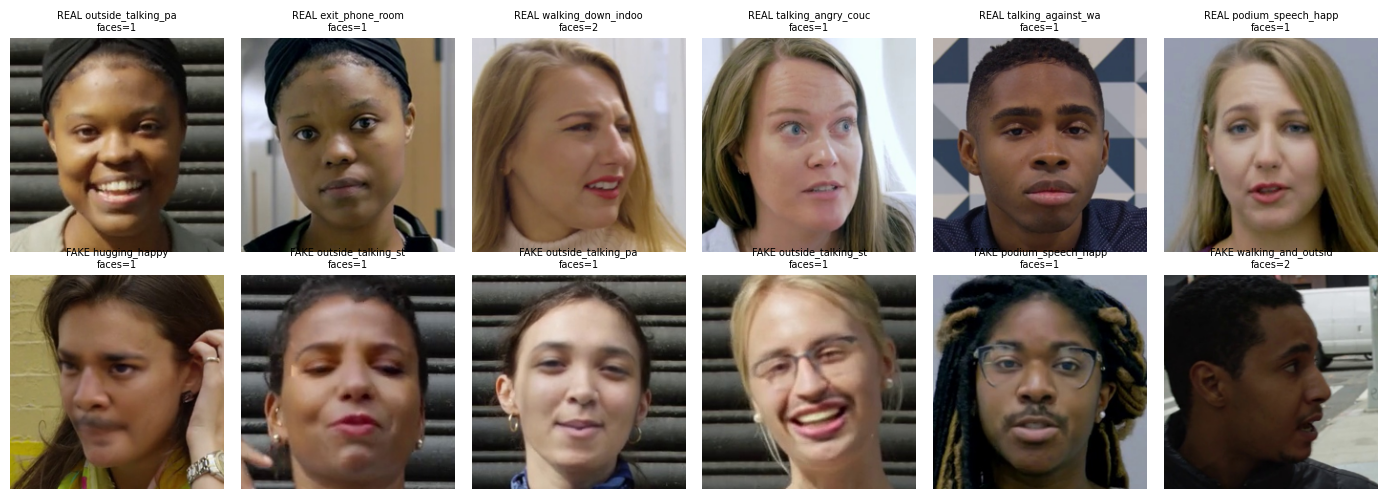

In [13]:
# 6.2 Example crops: 6 random real and 6 random fake videos (frame 16)
fig, axes = plt.subplots(2, 6, figsize=(14, 5))
for row, label in zip(axes, (0, 1)):
    vids = index[(index.label == label)].video_id.drop_duplicates().sample(6, random_state=SEED)
    for ax, vid in zip(row, vids):
        sub = index[(index.video_id == vid)]
        r = sub.iloc[(sub.frame_idx - 16).abs().argmin()]
        ax.imshow(Image.open(FACES_ROOT / r.path)); ax.axis("off")
        ax.set_title(f"{'FAKE' if label else 'REAL'} {r.scene[:18]}\nfaces={r.n_faces}", fontsize=7)
plt.tight_layout(); plt.show()